# Bike Rental Demand — EDA & Preprocessing Pipeline
**CSC 3730 Machine Learning Project · UCI Bike Sharing (hourly, `hour.csv`)**

It does three things:

1. **Understands the data** — quality checks and EDA plots focused on our question
   (casual vs. registered riders).
2. **Transforms it** — cleaning, feature engineering, the time-based train/test
   split, and scikit-learn preprocessors for linear and tree models.
3. **Shares it** — one function, `load_modeling_data()`, that every model owner
   calls so we all train and test on exactly the same data.

## Three ways to use it
| Where | How |
|---|---|
| Jupyter / Colab | Use `bike_eda_pipeline.ipynb` (same cells), or paste cells in order |
| VS Code | Open this `.py` — each `# %%` is a runnable cell |
| Your own model notebook | `from bike_eda_pipeline import load_modeling_data` |



**Requirements:** `pandas numpy matplotlib scikit-learn` (Python 3.9+).
Data is read only from this project's `data/hour.csv` (nothing is downloaded).
Paths are relative to the project folder, so the same notebook works on every
teammate's computer and in GitHub Actions CI.

In [13]:
from __future__ import annotations

import json
import sys
from pathlib import Path

import matplotlib
import numpy as np
import pandas as pd

if "ipykernel" not in sys.modules:          # running as a plain script
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def find_project_dir(start: str | Path | None = None) -> Path:
    """Return the project folder: the first of `start` (default: the current folder)
    and its parents that contains data/hour.csv. Works whether this notebook is run
    from the project root or from a subfolder such as results/."""
    start = Path(start or Path.cwd()).resolve()
    for folder in (start, *start.parents):
        if (folder / "data" / "hour.csv").is_file():
            return folder
    raise FileNotFoundError(
        f"Couldn't find data/hour.csv in {start} or any folder above it. "
        "Open the notebook from inside the project folder (e.g. 'CSC 3730/Final Project')."
    )


PROJECT_DIR = find_project_dir()
DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
FIG_DIR = PROJECT_DIR / "figures"

RANDOM_STATE = 42
# wewill model all three
TARGETS = ["casual", "registered", "cnt"]
TRAIN_END = pd.Timestamp("2012-09-30 23:00")         # train: Jan 2011 - Sep 2012
TEST_START = pd.Timestamp("2012-10-01 00:00")        # test:  Oct - Dec 2012

# The UCI file stores weather normalized to [0, 1]. These undo it for readable EDA.
TEMP_MAX_C, ATEMP_MAX_C, HUM_MAX, WIND_MAX = 41, 50, 100, 67

WEATHER_LABELS = {1: "Clear", 2: "Mist / cloudy", 3: "Light rain / snow"}
SEASON_LABELS = {1: "Winter", 2: "Spring", 3: "Summer", 4: "Fall"}
WEEKDAY_LABELS = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]

# Plot style: one fixed color per rider group, used in every figure.
# GENERATED WITH AI
COLORS = {"registered": "#2a78d6", "casual": "#eb6834", "cnt": "#1baf7a"}
NAMES = {"registered": "Registered", "casual": "Casual", "cnt": "Total"}
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SEQ_CMAP = LinearSegmentedColormap.from_list(
    "seq_blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIV_CMAP = LinearSegmentedColormap.from_list(
    "div_blue_red", ["#1c5cab", "#86b6ef", "#f0efec", "#f19a99", "#b42e2e"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "legend.frameon": False,
})


def _show(fig, name: str):
    """Save a figure to FIG_DIR; display it in notebooks, close it in scripts."""
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIG_DIR / f"{name}.png")
    if "ipykernel" in sys.modules:
        plt.show()
    else:
        plt.close(fig)

## 1. Load the raw data

In [14]:
def load_raw(path: str | Path | None = None) -> pd.DataFrame:
    """Read hour.csv from the project's data/ folder (or an explicit local path)."""
    path = Path(path) if path else DATA_DIR / "hour.csv"
    if not path.is_file():
        raise FileNotFoundError(f"{path} not found. Put the UCI hour.csv in the project's data/ folder.")
    return pd.read_csv(path)


if __name__ == "__main__":
    raw = load_raw()
    print(f"Loaded {DATA_DIR / 'hour.csv'}: {raw.shape}")
    display(raw.head()) 

Loaded /Users/kameron/Desktop/CSC 3730/Final Project/data/hour.csv: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## 2. Data quality checks
Checks every assumption the models rely on, and flags the known quirks of this dataset:
missing hours, a day of zero humidity readings, many zero wind speeds, and a rare
weather category.

In [15]:
def quality_report(df: pd.DataFrame) -> dict:
    """Print and return the data-quality findings for the raw hourly table."""
    ts = pd.to_datetime(df["dteday"]) + pd.to_timedelta(df["hr"], unit="h")
    full_range = pd.date_range(ts.min(), ts.max(), freq="h")
    missing_hours = full_range.difference(ts)
    missing_days = (pd.Series(missing_hours.normalize()).value_counts()
                    .loc[lambda s: s >= 12].sort_index())

    r = {
        "rows": len(df),
        "date_range": (str(ts.min()), str(ts.max())),
        "null_values": int(df.isna().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum()),
        "casual_plus_registered_equals_cnt": bool((df.casual + df.registered == df.cnt).all()),
        "expected_hours": len(full_range),
        "missing_hours": len(missing_hours),
        "days_missing_12plus_hours": [str(d.date()) for d in missing_days.index],
        "weathersit_counts": df.weathersit.value_counts().sort_index().to_dict(),
        "hum_zero_rows": int((df.hum == 0).sum()),
        "hum_zero_dates": sorted(df.loc[df.hum == 0, "dteday"].unique().tolist()),
        "windspeed_zero_rows": int((df.windspeed == 0).sum()),
        "windspeed_zero_pct": round(100 * (df.windspeed == 0).mean(), 1),
        "temp_atemp_corr": round(df.temp.corr(df.atemp), 3),
        "atemp_outlier_rows": int(((df.temp * TEMP_MAX_C) - (df.atemp * ATEMP_MAX_C) > 10).sum()),
        "skew": {t: round(float(df[t].skew()), 2) for t in TARGETS},
        "casual_share_pct": round(100 * df.casual.sum() / df.cnt.sum(), 1),
    }
    w = max(len(k) for k in r)
    for k, v in r.items():
        print(f"{k:<{w}}  {v}")
    return r


if __name__ == "__main__":
    qr = quality_report(raw)

rows                               17379
date_range                         ('2011-01-01 00:00:00', '2012-12-31 23:00:00')
null_values                        0
duplicate_rows                     0
casual_plus_registered_equals_cnt  True
expected_hours                     17544
missing_hours                      165
days_missing_12plus_hours          ['2011-01-18', '2011-01-27', '2012-10-29', '2012-10-30']
weathersit_counts                  {1: 11413, 2: 4544, 3: 1419, 4: 3}
hum_zero_rows                      22
hum_zero_dates                     ['2011-03-10']
windspeed_zero_rows                2180
windspeed_zero_pct                 12.5
temp_atemp_corr                    0.988
atemp_outlier_rows                 24
skew                               {'casual': 2.5, 'registered': 1.56, 'cnt': 1.28}
casual_share_pct                   18.8


## 3. Clean
| Issue | Fix | Why |
|---|---|---|
| No timestamp column | Build `datetime` from `dteday` + `hr` | Needed for the time split and plots |
| `weathersit = 4` (heavy rain) appears only a handful of times | Merge into 3 | Too rare to learn; would be an unseen category in the test set |
| Humidity = 0 for a full day (sensor failure) | Set to NaN, interpolate over time | 0 % humidity is physically impossible in D.C. |
| Wind speed = 0 on ~12 % of rows | **Kept**, reported | Could be calm air or missing data; teams can revisit |
| Missing hours (incl. Hurricane Sandy, Oct 29-30 2012, in the test set) | **Kept as missing** | No rentals were recorded; we don't invent them |

Readable-unit columns (`temp_c`, `hum_pct`, ...) are added for EDA only;
models use the normalized originals.

In [16]:
def clean(df: pd.DataFrame) -> pd.DataFrame:
    """
    Return a cleaned copy of the raw table with a datetime index column.
    """
    df = df.copy()
    df["datetime"] = pd.to_datetime(df["dteday"]) + pd.to_timedelta(df["hr"], unit="h")
    df = df.sort_values("datetime").reset_index(drop=True)

    df["weathersit"] = df["weathersit"].clip(upper=3)

    df["hum"] = df["hum"].replace(0, np.nan)
    df["hum"] = (df.set_index("datetime")["hum"]
                 .interpolate(method="time").bfill().ffill().to_numpy())

    # Readable units for EDA only
    df["temp_c"] = df["temp"] * TEMP_MAX_C
    df["atemp_c"] = df["atemp"] * ATEMP_MAX_C
    df["hum_pct"] = df["hum"] * HUM_MAX
    df["wind_kmh"] = df["windspeed"] * WIND_MAX
    df["casual_share"] = df["casual"] / df["cnt"]
    return df


if __name__ == "__main__":
    df = clean(raw)
    print(df[["datetime", "weathersit", "temp_c", "hum_pct", "wind_kmh"]].describe().round(2))

                         datetime  weathersit    temp_c   hum_pct  wind_kmh
count                       17379    17379.00  17379.00  17379.00  17379.00
mean   2012-01-02 15:41:22.858622        1.43     20.38     62.85     12.74
min           2011-01-01 00:00:00        1.00      0.82      8.00      0.00
25%           2011-07-04 22:30:00        1.00     13.94     48.00      7.00
50%           2012-01-02 21:00:00        1.00     20.50     63.00     13.00
75%           2012-07-02 06:30:00        2.00     27.06     78.00     17.00
max           2012-12-31 23:00:00        3.00     41.00    100.00     57.00
std                           NaN        0.64      7.89     19.20      8.20


## 4. Exploratory data analysis
Every plot compares **casual** (orange) and **registered** (blue) riders, since
that difference is the point of the project.

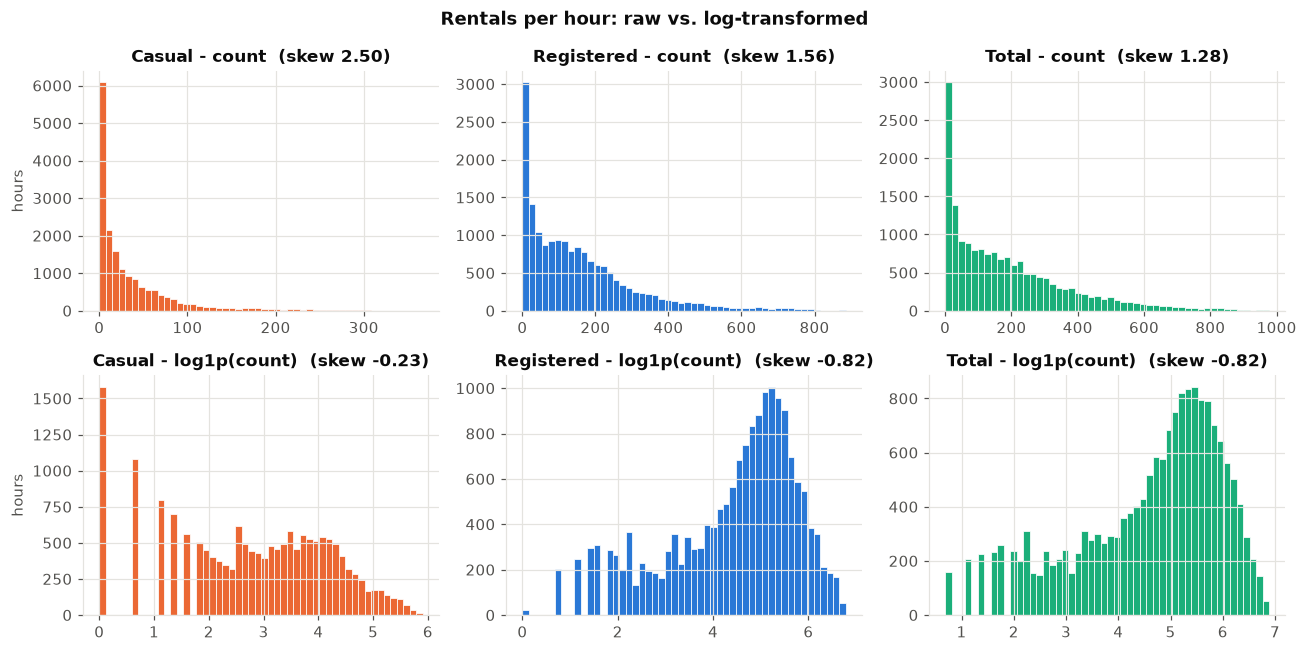

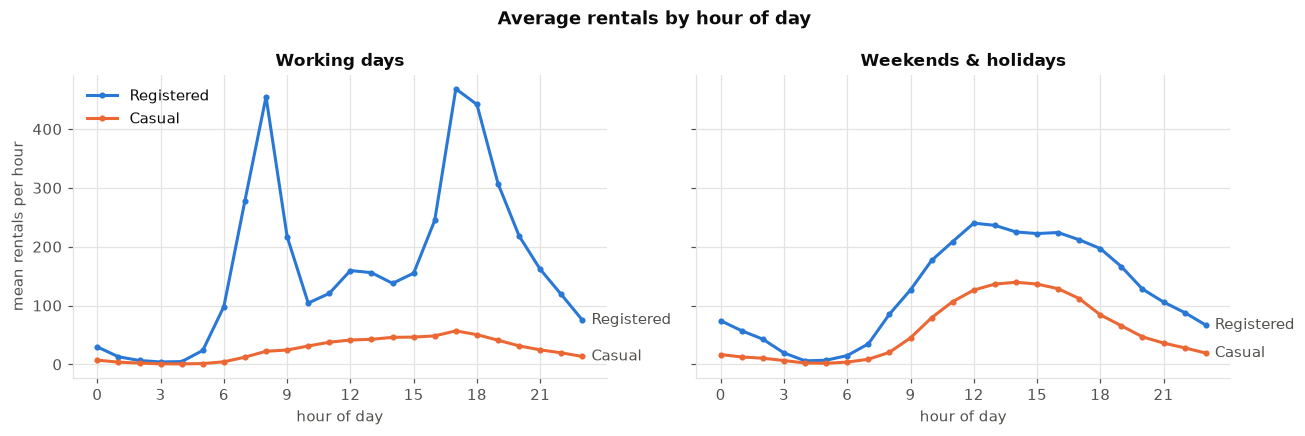

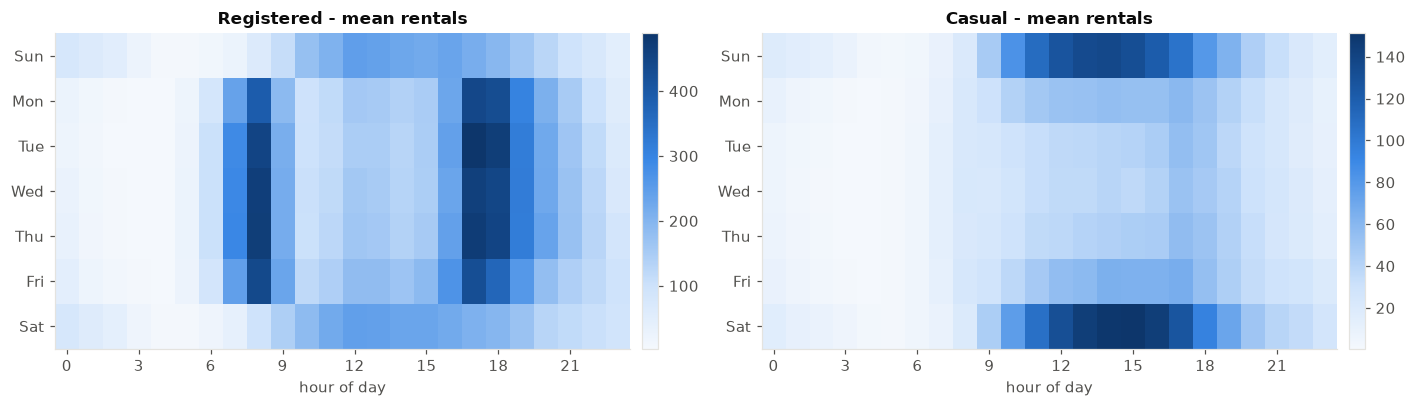

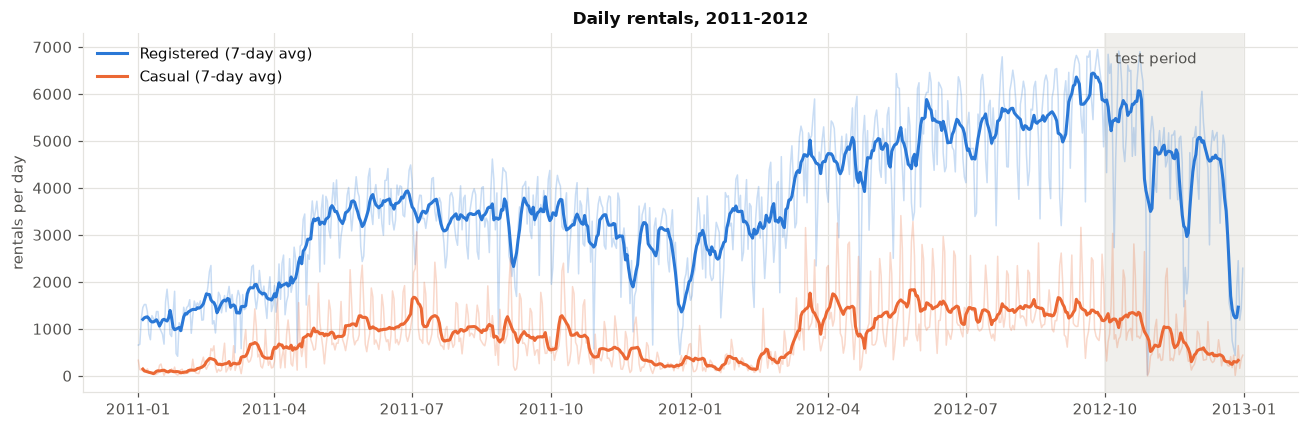

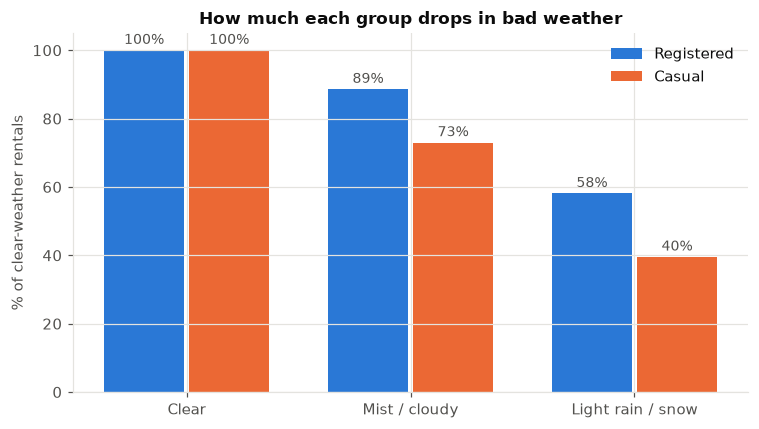

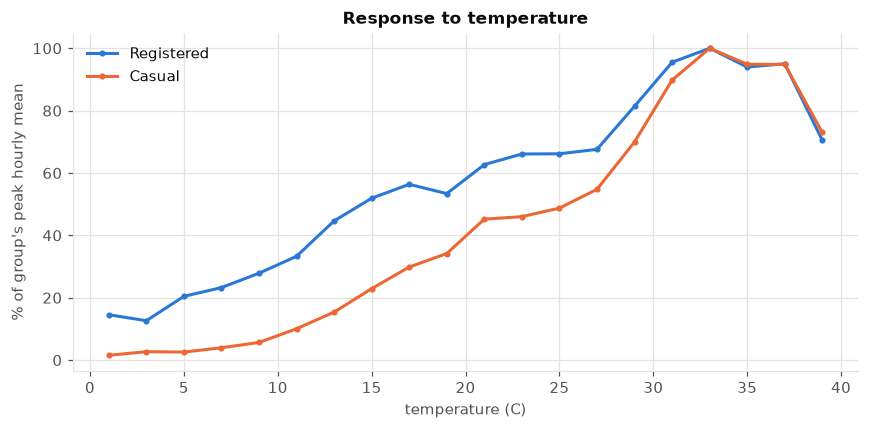

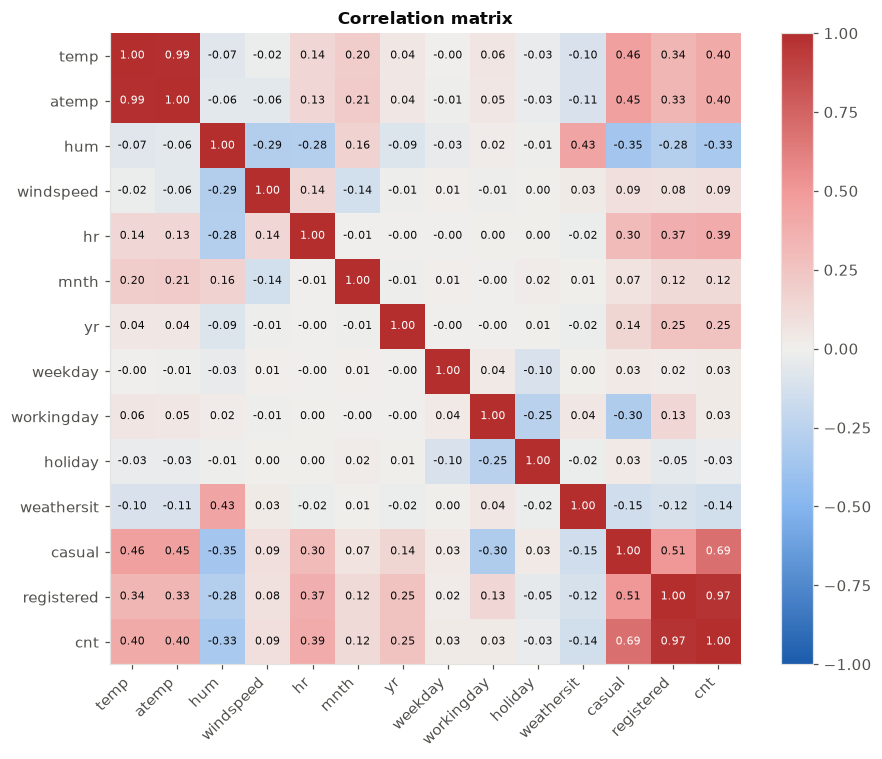

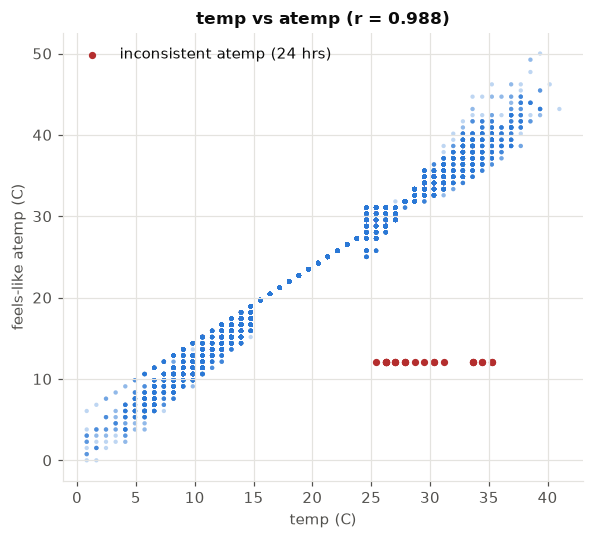

                            Registered  Casual
share of all rentals (%)         81.17   18.83
mean per hour                   153.79   35.68
working-day peak hour            17.00   17.00
weekend peak hour                12.00   14.00
weekend / working-day mean        0.74    2.25
light rain as % of clear         58.10   39.53
corr with temp                    0.34    0.46
2012 / 2011 growth                1.68    1.51


In [17]:
"""Graphs were generated with the assistance of AI, but the analysis and conclusions are human-written."""

def plot_target_distributions(df):
    """Raw counts are heavily right-skewed; log1p makes them far more symmetric."""
    fig, axes = plt.subplots(2, 3, figsize=(12, 6))
    for j, t in enumerate(TARGETS):
        for i, (vals, label) in enumerate([(df[t], "count"), (np.log1p(df[t]), "log1p(count)")]):
            ax = axes[i, j]
            ax.hist(vals, bins=50, color=COLORS[t], edgecolor="white", linewidth=0.5)
            ax.set_title(f"{NAMES[t]} - {label}  (skew {vals.skew():.2f})")
            ax.set_ylabel("hours" if j == 0 else "")
    fig.suptitle("Rentals per hour: raw vs. log-transformed", fontweight="bold")
    fig.tight_layout()
    _show(fig, "01_target_distributions")


def plot_hourly_profiles(df):
    """The core finding: registered riders commute, casual riders don't."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
    for ax, (wd, title) in zip(axes, [(1, "Working days"), (0, "Weekends & holidays")]):
        sub = df[df.workingday == wd].groupby("hr")[["registered", "casual"]].mean()
        for t in ["registered", "casual"]:
            ax.plot(sub.index, sub[t], color=COLORS[t], label=NAMES[t], marker="o", ms=3)
            ax.annotate(NAMES[t], (23, sub[t].iloc[-1]), xytext=(6, 0),
                        textcoords="offset points", va="center", color=INK_2)
        ax.set_title(title)
        ax.set_xlabel("hour of day")
        ax.set_xticks(range(0, 24, 3))
    axes[0].set_ylabel("mean rentals per hour")
    axes[0].legend(loc="upper left")
    fig.suptitle("Average rentals by hour of day", fontweight="bold")
    fig.tight_layout()
    _show(fig, "02_hourly_profiles")


def plot_hour_weekday_heatmaps(df):
    """Hour x weekday grid for each group (each panel has its own color scale)."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
    for ax, t in zip(axes, ["registered", "casual"]):
        grid = df.pivot_table(index="weekday", columns="hr", values=t, aggfunc="mean")
        im = ax.imshow(grid, aspect="auto", cmap=SEQ_CMAP)
        ax.set_yticks(range(7), WEEKDAY_LABELS)
        ax.set_xticks(range(0, 24, 3))
        ax.set_xlabel("hour of day")
        ax.set_title(f"{NAMES[t]} - mean rentals")
        ax.grid(False)
        fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
    fig.tight_layout()
    _show(fig, "03_hour_weekday_heatmaps")


def plot_daily_trend(df):
    """Daily totals over two years: growth, seasonality, and where the test set sits."""
    daily = df.set_index("datetime")[["registered", "casual"]].resample("D").sum()
    roll = daily.rolling(7, center=True).mean()
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.axvspan(TEST_START, daily.index.max(), color="#f0efec", zorder=0)
    ax.text(TEST_START, roll.max().max() * 1.02, "  test period", color=INK_2, va="bottom")
    for t in ["registered", "casual"]:
        ax.plot(daily.index, daily[t], color=COLORS[t], alpha=0.25, linewidth=1)
        ax.plot(roll.index, roll[t], color=COLORS[t], label=f"{NAMES[t]} (7-day avg)")
    ax.set_ylabel("rentals per day")
    ax.legend(loc="upper left")
    ax.set_title("Daily rentals, 2011-2012")
    fig.tight_layout()
    _show(fig, "04_daily_trend")


def plot_weather_sensitivity(df):
    """Mean rentals in each weather category, as % of that group's clear-weather level."""
    m = df.groupby("weathersit")[["registered", "casual"]].mean()
    rel = 100 * m / m.loc[1]
    x = np.arange(len(rel))
    fig, ax = plt.subplots(figsize=(7, 4))
    for k, t in enumerate(["registered", "casual"]):
        bars = ax.bar(x + (k - 0.5) * 0.38, rel[t], width=0.36, color=COLORS[t], label=NAMES[t])
        ax.bar_label(bars, fmt="%.0f%%", padding=2, color=INK_2, fontsize=9)
    ax.set_xticks(x, [WEATHER_LABELS[i] for i in rel.index])
    ax.set_ylabel("% of clear-weather rentals")
    ax.set_title("How much each group drops in bad weather")
    ax.legend()
    fig.tight_layout()
    _show(fig, "05_weather_sensitivity")


def plot_temperature_response(df):
    """Mean rentals by 2 C temperature bin, scaled to each group's peak."""
    bins = np.arange(-8, 42, 2)
    tb = pd.cut(df.temp_c, bins)
    m = df.groupby(tb, observed=True)[["registered", "casual"]].mean()
    centers = [iv.mid for iv in m.index]
    fig, ax = plt.subplots(figsize=(8, 4))
    for t in ["registered", "casual"]:
        ax.plot(centers, 100 * m[t] / m[t].max(), color=COLORS[t], label=NAMES[t], marker="o", ms=3)
    ax.set_xlabel("temperature (C)")
    ax.set_ylabel("% of group's peak hourly mean")
    ax.set_title("Response to temperature")
    ax.legend()
    fig.tight_layout()
    _show(fig, "06_temperature_response")


def plot_correlations(df):
    """Correlation of candidate features with each target..."""
    cols = ["temp", "atemp", "hum", "windspeed", "hr", "mnth", "yr", "weekday",
            "workingday", "holiday", "weathersit", "casual", "registered", "cnt"]
    c = df[cols].corr()
    fig, ax = plt.subplots(figsize=(8.5, 7))
    im = ax.imshow(c, cmap=DIV_CMAP, vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
    ax.set_yticks(range(len(cols)), cols)
    ax.grid(False)
    for i in range(len(cols)):
        for j in range(len(cols)):
            v = c.iloc[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(v) > 0.6 else INK)
    fig.colorbar(im, ax=ax, fraction=0.04)
    ax.set_title("Correlation matrix")
    fig.tight_layout()
    _show(fig, "07_correlations")


def plot_temp_vs_atemp(df):
    """
    Plotting temperature vs feels-like temperature (atemp) to identify any inconsistencies in the data.
    """
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.scatter(df.temp_c, df.atemp_c, s=8, alpha=0.3, color=COLORS["registered"],
               edgecolors="none")
    odd = (df.temp_c - df.atemp_c) > 10
    ax.scatter(df.temp_c[odd], df.atemp_c[odd], s=14, color="#b42e2e",
               label=f"inconsistent atemp ({odd.sum()} hrs)")
    ax.set_xlabel("temp (C)")
    ax.set_ylabel("feels-like atemp (C)")
    ax.set_title(f"temp vs atemp (r = {df.temp.corr(df.atemp):.3f})")
    ax.legend(loc="upper left")
    fig.tight_layout()
    _show(fig, "08_temp_vs_atemp")


def eda_summary(df) -> pd.DataFrame:
    """
    Key numbers behind the plots, per rider group.
    """
    rows = {}
    for t in ["registered", "casual"]:
        wd = df[df.workingday == 1].groupby("hr")[t].mean()
        we = df[df.workingday == 0].groupby("hr")[t].mean()
        w = df.groupby("weathersit")[t].mean()
        rows[NAMES[t]] = {
            "share of all rentals (%)": 100 * df[t].sum() / df.cnt.sum(),
            "mean per hour": df[t].mean(),
            "working-day peak hour": int(wd.idxmax()),
            "weekend peak hour": int(we.idxmax()),
            "weekend / working-day mean": df[df.workingday == 0][t].mean()
                                          / df[df.workingday == 1][t].mean(),
            "light rain as % of clear": 100 * w.loc[3] / w.loc[1],
            "corr with temp": df[t].corr(df.temp),
            "2012 / 2011 growth": df[df.yr == 1][t].sum() / df[df.yr == 0][t].sum(),
        }
    return pd.DataFrame(rows).round(2)


if __name__ == "__main__":
    plot_target_distributions(df)
    plot_hourly_profiles(df)
    plot_hour_weekday_heatmaps(df)
    plot_daily_trend(df)
    plot_weather_sensitivity(df)
    plot_temperature_response(df)
    plot_correlations(df)
    plot_temp_vs_atemp(df)
    print(eda_summary(df))

### What the EDA tells us (and the transform each finding drives)
| Finding | Transform |
|---|---|
| All three targets are strongly right-skewed (many near-zero hours) | Models predict `log1p(count)`; convert back with `expm1` |
| Registered riders peak at 8 am and 5-6 pm on working days; casual riders peak mid-afternoon and ride ~2.3x more per hour on weekends | Hour **and** working day matter *together* -> `hour_workday` feature (48 levels) for linear models; trees get raw `hr` + `workingday`. (Checked: with a Ridge model this cut registered test RMSLE from 0.91 to 0.45.) |
| Hour, month and weekday are cycles (hour 23 is next to hour 0) | sin/cos encodings |
| `temp` and `atemp` correlate at 0.99, and `atemp` has 24 bad readings | Drop `atemp` |
| Casual riders fall off far more in rain (to ~40 % of clear-day levels vs ~58 % for registered) and in cold | Keep weather features un-binned; compare their importance across group models |
| Ridership grew ~1.6x from 2011 to 2012 | Keep `yr`; the test period (late 2012) is at the higher level |
| The test period is late autumn/winter: casual share is 14.5 % vs 19.6 % in training, and Hurricane Sandy wiped out Oct 29-30 | Expect casual errors to look different in test than in CV; mention it when reporting results |
| `casual` + `registered` = `cnt` exactly | **Never** use one target as a feature for another (leakage) |

## 5. Feature engineering

In [18]:
CYCLICAL = {"hr": 24, "mnth": 12, "weekday": 7}
BINARY_FEATURES = ["yr", "holiday", "workingday"]
WEATHER_NUMERIC = ["temp", "hum", "windspeed"]
CYCLICAL_FEATURES = [f"{c}_{f}" for c in CYCLICAL for f in ("sin", "cos")]

# Linear model sclaing: scaled numerics + one-hot categoricals
LINEAR_NUMERIC = WEATHER_NUMERIC
LINEAR_CATEGORICAL = ["season", "weathersit", "hour_workday"]
LINEAR_PASSTHROUGH = BINARY_FEATURES + CYCLICAL_FEATURES
LINEAR_FEATURES = LINEAR_NUMERIC + LINEAR_CATEGORICAL + LINEAR_PASSTHROUGH

# Tree models (random forest, gradient boosting): raw integers split fine, no scaling
TREE_FEATURES = (["hr", "mnth", "weekday", "season", "weathersit"]
                 + BINARY_FEATURES + WEATHER_NUMERIC + CYCLICAL_FEATURES)

EXCLUDED = ["instant", "dteday", "datetime", "atemp", *TARGETS]


def build_features(df: pd.DataFrame) -> pd.DataFrame:
    """Add engineered features to a cleaned table. Uses only same-row values, so it
    is safe to run before the split (nothing is learned from other rows)."""
    out = df.copy()
    for col, period in CYCLICAL.items():
        out[f"{col}_sin"] = np.sin(2 * np.pi * out[col] / period)
        out[f"{col}_cos"] = np.cos(2 * np.pi * out[col] / period)
    out["hour_workday"] = out["hr"] + 24 * out["workingday"]
    return out


if __name__ == "__main__":
    feat = build_features(df)
    print(f"{len(LINEAR_FEATURES)} linear features, {len(TREE_FEATURES)} tree features")

15 linear features, 17 tree features


## 6. Time-based train/test split
Splits based on time, because a random split would let the model see the future. The test period is Oct-Dec 2012, which is held out and touched only once.

In [19]:
def time_split(df: pd.DataFrame):
    """Train: Jan 2011 - Sep 2012. Test: Oct - Dec 2012 (held out, touch once)."""
    train = df[df.datetime <= TRAIN_END].reset_index(drop=True)
    test = df[df.datetime >= TEST_START].reset_index(drop=True)
    return train, test


def time_series_cv(n_splits: int = 5) -> TimeSeriesSplit:
    """Expanding-window CV for tuning; pass as `cv=` to GridSearchCV etc."""
    return TimeSeriesSplit(n_splits=n_splits)


if __name__ == "__main__":
    train, test = time_split(feat)
    for name, part in [("train", train), ("test", test)]:
        print(f"{name:5s} {len(part):6d} rows  {part.datetime.min()} -> {part.datetime.max()}"
              f"  casual share {100 * part.casual.sum() / part.cnt.sum():.1f}%")

train  15211 rows  2011-01-01 00:00:00 -> 2012-09-30 23:00:00  casual share 19.6%
test    2168 rows  2012-10-01 00:00:00 -> 2012-12-31 23:00:00  casual share 14.5%


## 7. Preprocessors (fit on training data only)
These are scikit-learn `ColumnTransformer`s. Put them **inside** a `Pipeline` with your
model so scaling and encoding are learned from the training folds only:
```python
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
model = make_pipeline(make_preprocessor("linear"), Ridge())
model.fit(X_train, y_train["registered"])
```

In [20]:
def make_preprocessor(kind: str = "linear") -> ColumnTransformer:
    """'linear' -> scale weather, one-hot categoricals; 'tree' -> select columns as-is."""
    if kind == "linear":
        return ColumnTransformer([
            ("num", StandardScaler(), LINEAR_NUMERIC),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), LINEAR_CATEGORICAL),
            ("pass", "passthrough", LINEAR_PASSTHROUGH),
        ], verbose_feature_names_out=False)
    if kind == "tree":
        return ColumnTransformer([("pass", "passthrough", TREE_FEATURES)],
                                 verbose_feature_names_out=False)
    raise ValueError("kind must be 'linear' or 'tree'")


if __name__ == "__main__":
    pre = make_preprocessor("linear").fit(train)
    print("linear design matrix:", pre.transform(train).shape)
    print("tree design matrix:  ", make_preprocessor("tree").fit_transform(train).shape)

linear design matrix: (15211, 67)
tree design matrix:   (15211, 17)


## 9. Export for the team
Writes `data/processed/train.csv`, `test.csv` and `feature_config.json`, so anyone can
load the exact same data without re-running the EDA.

In [22]:
def export_processed(train: pd.DataFrame, test: pd.DataFrame, out_dir: Path = PROCESSED_DIR):
    """
    Generated with AI.

    Exports the processed training and test data along with a feature configuration file.
    :param train:
    :param test:
    :param out_dir:
    :return:
    """
    out_dir.mkdir(parents=True, exist_ok=True)
    keep = ["datetime", *sorted(set(LINEAR_FEATURES + TREE_FEATURES)), *TARGETS]
    train[keep].to_csv(out_dir / "train.csv", index=False)
    test[keep].to_csv(out_dir / "test.csv", index=False)
    config = {
        "train_period": [str(train.datetime.min()), str(train.datetime.max())],
        "test_period": [str(test.datetime.min()), str(test.datetime.max())],
        "targets": TARGETS,
        "target_transform": "log1p (invert with expm1, clip at 0)",
        "linear_features": {"numeric_scaled": LINEAR_NUMERIC, "one_hot": LINEAR_CATEGORICAL,
                            "passthrough": LINEAR_PASSTHROUGH},
        "tree_features": TREE_FEATURES,
        "excluded": EXCLUDED,
        "metrics": ["RMSE", "MAE", "RMSLE"],
        "random_state": RANDOM_STATE,
    }
    (out_dir / "feature_config.json").write_text(json.dumps(config, indent=2))
    print(f"wrote {out_dir}/train.csv ({len(train)} rows), test.csv ({len(test)} rows), feature_config.json")


if __name__ == "__main__":
    export_processed(train, test)

wrote /Users/kameron/Desktop/CSC 3730/Final Project/data/processed/train.csv (15211 rows), test.csv (2168 rows), feature_config.json


## 10. The one function model owners need
```python
from bike_eda_pipeline import load_modeling_data, make_preprocessor, evaluate, to_counts
X_train, X_test, y_train, y_test = load_modeling_data()
# y_train / y_test are DataFrames with columns casual, registered, cnt (raw counts)
```

In [23]:
def load_modeling_data(path: str | Path | None = None, log_target: bool = False):
    """Load -> clean -> engineer -> split. Returns X_train, X_test, y_train, y_test.

    Abstracts all the extraction code.

    X frames hold every engineered column (pick LINEAR_FEATURES or TREE_FEATURES, or
    just use make_preprocessor). y frames hold casual / registered / cnt; set
    log_target=True to get log1p(counts) for regression models. Poisson / count
    models should use the raw counts (log_target=False).
    """
    data = build_features(clean(load_raw(path)))
    train, test = time_split(data)
    X_cols = sorted(set(LINEAR_FEATURES + TREE_FEATURES))
    y_train, y_test = train[TARGETS].astype(float), test[TARGETS].astype(float)
    if log_target:
        y_train, y_test = np.log1p(y_train), np.log1p(y_test)
    return train[X_cols], test[X_cols], y_train, y_test


if __name__ == "__main__":
    X_train, X_test, y_train, y_test = load_modeling_data()
    print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(15211, 18) (2168, 18) (15211, 3) (2168, 3)
